In [1]:
import json
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

from results_loader import (MODELS, MODEL_LABELS, load_all, task_thresholds, asr_found, intent_hit, tex_name, pretty, setup_latex_plots, PCT, ordered, method_color)
from stats_utils import bootstrap_ci, wilson_ci, fmt_ci, comparison_table
import paper_tables as pt

setup_latex_plots()
EXCLUDE_BASELINE_FAILURES = True  # True: drop sentences whose clean input already fails (ASR) / maps to the wrong intent
ROOT = "../outputs/results"
PRIMARY = MODELS[0]  # model of the single-model displays (spectrograms)

# baseline failures: clean input already fails (ASR: transcription != ground truth; intent: clean intent != reference)
asr_raw, intent_raw = load_all(ROOT, exclude_baseline_failures=False)
for model in MODELS:
    print(model, "baseline failures ASR:", {m: f"{np.mean([not r['original_passes'] for r in rs]):.1%}" for m, rs in asr_raw[model].items()})
    print(model, "baseline failures intent:", {m: f"{np.mean([not r['intent']['original_correct'] for r in rs]):.1%}" for m, rs in intent_raw[model].items()})

asr, intent = load_all(ROOT, exclude_baseline_failures=EXCLUDE_BASELINE_FAILURES)  # {model: {method: records}}
thr = task_thresholds(asr, intent)  # m-valid UTMOS thresholds per task
for model in MODELS:
    print(model, "n ASR:", {m: len(rs) for m, rs in asr[model].items()}, "| n intent:", {m: len(rs) for m, rs in intent[model].items()})

whisper-tiny baseline failures ASR: {'GATAS': '29.0%', 'Waveform': '29.0%', 'SMACK_untargeted': '28.0%', 'ALIF': '28.0%', 'PGD': '28.0%', 'SMACK': '28.0%'}
whisper-tiny baseline failures intent: {'GATAS': '2.0%', 'Waveform': '2.0%', 'SMACK': '2.0%', 'ALIF': '2.0%', 'PGD': '2.0%', 'GATAS_llm': '2.0%'}
wav2vec2-large baseline failures ASR: {'GATAS': '8.0%', 'Waveform': '8.0%', 'SMACK_untargeted': '8.0%', 'ALIF': '8.0%', 'SMACK': '8.0%'}
wav2vec2-large baseline failures intent: {'GATAS': '42.0%', 'Waveform': '42.0%', 'SMACK': '42.0%', 'ALIF': '42.0%', 'GATAS_llm': '42.0%'}
whisper-tiny n ASR: {'GATAS': 71, 'Waveform': 71, 'SMACK_untargeted': 72, 'ALIF': 72, 'PGD': 72, 'SMACK': 72} | n intent: {'GATAS': 98, 'Waveform': 98, 'SMACK': 98, 'ALIF': 98, 'PGD': 98, 'GATAS_llm': 98}
wav2vec2-large n ASR: {'GATAS': 92, 'Waveform': 92, 'SMACK_untargeted': 92, 'ALIF': 92, 'SMACK': 92} | n intent: {'GATAS': 58, 'Waveform': 58, 'SMACK': 58, 'ALIF': 58, 'GATAS_llm': 58}


## a) ASR task: effectiveness measures
Success = transcription differs from ground truth (Wilson 95% CI); quality measures are means with bootstrap 95% CI.

In [2]:
def effectiveness_table(records, extra=()):
    rows = {}
    for m, recs in records.items():
        if not recs:
            continue
        k, n = sum(r["success"] for r in recs), len(recs)
        row = {"n": n, "test case found %": fmt_ci(k / n, *wilson_ci(k, n), digits=1, scale=100)}
        for name, key in (("lexical (WER)", "wer"), ("semantic", "semantic"), ("spectrogram", "spectrogram"), ("UTMOS", "utmos")):
            v = [r[key] for r in recs]
            row[name] = fmt_ci(np.mean(v), *bootstrap_ci(v), digits=3)
        for name, fn in extra:
            row[name] = fn(recs)
        rows[m] = row
    return pd.DataFrame(rows).T

for model in MODELS:
    print(f"== {MODEL_LABELS[model]}")
    display(pretty(effectiveness_table(asr[model])))
    print(f"clean-audio UTMOS: {np.mean([r['utmos_original'] for r in next(iter(asr[model].values()))]):.3f}")

== Whisper-tiny


,n,test case found %,lexical (WER),semantic,spectrogram,UTMOS
GATAS,71,"88.7 [79.3, 94.2]","0.191 [0.154, 0.232]","0.230 [0.191, 0.271]","0.068 [0.063, 0.074]","4.203 [4.115, 4.273]"
Waveform,71,"100.0 [94.9, 100.0]","1.180 [0.993, 1.549]","0.929 [0.917, 0.941]","0.160 [0.152, 0.167]","1.369 [1.343, 1.398]"
SMACK‡,72,"90.3 [81.3, 95.2]","1.202 [0.742, 1.771]","0.692 [0.611, 0.771]","0.190 [0.184, 0.196]","2.570 [2.348, 2.791]"
ALIF,72,"100.0 [94.9, 100.0]","1.244 [0.611, 2.113]","0.692 [0.652, 0.732]","0.192 [0.185, 0.201]","2.586 [2.482, 2.689]"
PGD,72,"100.0 [94.9, 100.0]","1.456 [1.108, 2.080]","0.896 [0.870, 0.920]","0.045 [0.044, 0.046]","3.937 [3.891, 3.982]"
SMACK,72,"69.4 [58.0, 78.9]","0.661 [0.325, 1.236]","0.352 [0.270, 0.439]","0.191 [0.186, 0.196]","3.193 [2.986, 3.401]"


clean-audio UTMOS: 4.392
== wav2vec2-large


,n,test case found %,lexical (WER),semantic,spectrogram,UTMOS
GATAS,92,"93.5 [86.5, 97.0]","0.161 [0.140, 0.184]","0.189 [0.157, 0.222]","0.075 [0.071, 0.080]","4.187 [4.125, 4.245]"
Waveform,92,"100.0 [96.0, 100.0]","0.988 [0.970, 1.000]","0.914 [0.899, 0.927]","0.148 [0.140, 0.156]","1.350 [1.328, 1.375]"
SMACK‡,92,"84.8 [76.1, 90.7]","0.610 [0.521, 0.696]","0.504 [0.433, 0.575]","0.188 [0.182, 0.195]","2.885 [2.660, 3.092]"
ALIF,92,"100.0 [96.0, 100.0]","0.548 [0.511, 0.586]","0.588 [0.548, 0.629]","0.189 [0.185, 0.192]","2.623 [2.531, 2.712]"
SMACK,92,"73.9 [64.1, 81.8]","0.341 [0.274, 0.412]","0.284 [0.229, 0.344]","0.191 [0.186, 0.195]","3.343 [3.199, 3.487]"


clean-audio UTMOS: 4.390


## b) Intent matching task
*intent changed*: adversarial transcription classified as another intent than the clean one. *target hit*: changed to the target intent (untargeted methods: by chance).

In [3]:
def intent_extra(recs):
    n = len(recs)
    ch = sum(r["intent"]["changed"] for r in recs)
    hit = sum(intent_hit(r) for r in recs)
    return fmt_ci(ch / n, *wilson_ci(ch, n), digits=1, scale=100), fmt_ci(hit / n, *wilson_ci(hit, n), digits=1, scale=100)

for model in MODELS:
    print(f"== {MODEL_LABELS[model]}")
    tab = effectiveness_table(intent[model])
    tab.insert(1, "intent changed %", [intent_extra(intent[model][m])[0] for m in tab.index])
    tab.insert(2, "target hit %", [intent_extra(intent[model][m])[1] for m in tab.index])
    display(pretty(tab))

== Whisper-tiny


,n,intent changed %,target hit %,test case found %,lexical (WER),semantic,spectrogram,UTMOS
GATAS,98,"20.4 [13.6, 29.4]","9.2 [4.9, 16.5]","99.0 [94.4, 99.8]","0.265 [0.231, 0.302]","0.246 [0.203, 0.292]","0.070 [0.065, 0.075]","4.185 [4.121, 4.247]"
Waveform,98,"82.7 [74.0, 88.9]","20.4 [13.6, 29.4]","96.9 [91.4, 99.0]","0.802 [0.737, 0.864]","0.717 [0.661, 0.770]","0.152 [0.142, 0.162]","1.397 [1.358, 1.443]"
SMACK,98,"45.9 [36.4, 55.8]","6.1 [2.8, 12.7]","83.7 [75.1, 89.7]","1.558 [0.784, 2.563]","0.475 [0.399, 0.551]","0.194 [0.185, 0.202]","3.105 [2.922, 3.278]"
ALIF,98,"66.3 [56.5, 74.9]","36.7 [27.9, 46.6]","99.0 [94.4, 99.8]","0.472 [0.420, 0.525]","0.475 [0.431, 0.518]","0.194 [0.185, 0.203]","2.584 [2.499, 2.665]"
PGD,98,"91.8 [84.7, 95.8]","6.1 [2.8, 12.7]","100.0 [96.2, 100.0]","1.421 [1.276, 1.600]","0.898 [0.877, 0.920]","0.046 [0.044, 0.049]","3.919 [3.871, 3.962]"
GATAS†,98,"84.7 [76.3, 90.5]","73.5 [64.0, 81.2]","96.9 [91.4, 99.0]","0.494 [0.430, 0.560]","0.477 [0.431, 0.523]","0.105 [0.099, 0.111]","4.154 [4.100, 4.203]"


== wav2vec2-large


,n,intent changed %,target hit %,test case found %,lexical (WER),semantic,spectrogram,UTMOS
GATAS,58,"15.5 [8.4, 26.9]","0.0 [0.0, 6.2]","96.6 [88.3, 99.0]","0.220 [0.188, 0.257]","0.212 [0.167, 0.258]","0.071 [0.065, 0.077]","4.242 [4.159, 4.311]"
Waveform,58,"84.5 [73.1, 91.6]","19.0 [10.9, 30.9]","94.8 [85.9, 98.2]","0.852 [0.773, 0.924]","0.777 [0.705, 0.841]","0.147 [0.135, 0.159]","1.380 [1.335, 1.432]"
SMACK,58,"32.8 [22.1, 45.6]","1.7 [0.3, 9.1]","86.2 [75.1, 92.8]","0.529 [0.415, 0.658]","0.384 [0.309, 0.464]","0.196 [0.185, 0.209]","3.114 [2.900, 3.312]"
ALIF,58,"56.9 [44.1, 68.8]","24.1 [15.0, 36.5]","100.0 [93.8, 100.0]","0.502 [0.438, 0.572]","0.522 [0.467, 0.580]","0.199 [0.188, 0.210]","2.550 [2.430, 2.663]"
GATAS†,58,"70.7 [58.0, 80.8]","43.1 [31.2, 55.9]","96.6 [88.3, 99.0]","0.471 [0.398, 0.550]","0.465 [0.407, 0.525]","0.106 [0.098, 0.114]","4.139 [4.064, 4.206]"


### Effectiveness vs. naturalness
Mean with 95% CI (Wilson for rates, bootstrap for UTMOS). Top right is best: more test cases found, closer to natural speech (clean-audio UTMOS dashed).

Pooled over the attacked ASR models (sentences of all models together; PGD is white-box on Whisper and enters with Whisper only).

pooled n ASR: {'GATAS': 163, 'SMACK': 164, 'SMACK_untargeted': 164, 'PGD': 72, 'Waveform': 163, 'ALIF': 164} | intent: {'GATAS': 156, 'SMACK': 156, 'PGD': 98, 'Waveform': 156, 'GATAS_llm': 156, 'ALIF': 156}


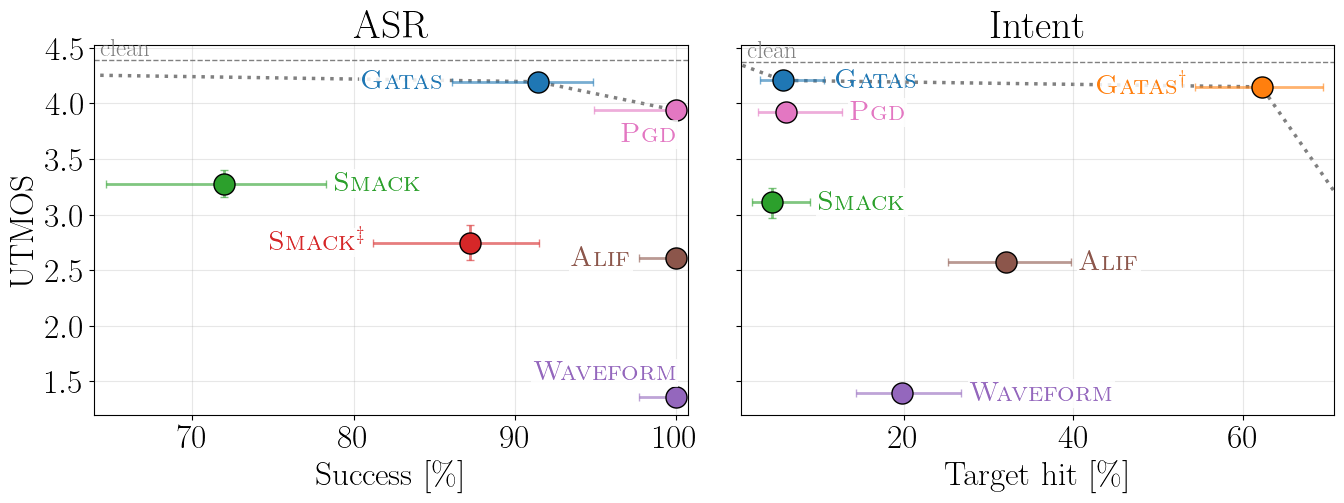

In [4]:
def tradeoff_panel(ax, records, success_fn, ylabel, title, x_key="utmos", clean_x=None, first=True):
    pts = []
    for m, recs in records.items():
        n = len(recs)
        k = sum(success_fn(r) for r in recs)
        y, (ylo, yhi) = k / n, wilson_ci(k, n)
        xs = [r[x_key] for r in recs]
        x, (xlo, xhi) = np.mean(xs), bootstrap_ci(xs)
        ax.errorbar(100 * y, x, xerr=[[100 * max(y - ylo, 0)], [100 * max(yhi - y, 0)]], yerr=[[max(x - xlo, 0)], [max(xhi - x, 0)]],
                    fmt="none", ecolor=method_color(m), alpha=0.6, lw=2, capsize=3, zorder=2)
        ax.scatter(100 * y, x, s=230, color=method_color(m), edgecolor="black", zorder=3)
        pts.append((m, 100 * y, x, method_color(m), 100 * yhi, 100 * ylo))
    ax.set_xlabel(ylabel + " [" + PCT + "]"); ax.set_ylabel("UTMOS" if first else ""); ax.set_title(title)
    ax.grid(alpha=0.3)

    # limits: data range plus a 2 % margin on both sides (rates never exceed 100 %); fixed so the front line cannot widen them
    lo_min, hi_max = min(p[5] for p in pts), max(p[4] for p in pts)
    margin = 0.02 * (hi_max - lo_min)
    ax.set_xlim(lo_min - margin, hi_max + margin)
    ax.set_xticks([t for t in ax.get_xticks() if 0 <= t <= 100 and lo_min - margin <= t <= hi_max + margin])
    ax.set_xlim(lo_min - margin, hi_max + margin)
    if clean_x is not None:
        ax.set_ylim(top=clean_x + 0.15)
    ax.autoscale(False)
    x0, x1 = ax.get_xlim()

    # clean-audio reference (dashed) and Pareto front (dotted) over the means: starts at (0, clean), ends horizontally at 100 %
    if clean_x is not None:
        ax.axhline(clean_x, color="gray", ls="--", lw=1)
        ax.text(x0 + 0.01 * (x1 - x0), clean_x, "clean", va="bottom", color="gray", fontsize=18)
    # anchors: no attack (0 % success, clean UTMOS) and a trivial 100 % success with UTMOS 0; they stay on the front unless dominated
    anchors = ([("clean", 0.0, clean_x)] if clean_x is not None else []) + [("max", 100.0, 0.0)]
    cand = [(p[0], p[1], p[2]) for p in pts] + anchors
    eps = 1e-9
    front = sorted([c for c in cand if not any(o is not c and o[1] >= c[1] - eps and o[2] >= c[2] - eps and (o[1] > c[1] + eps or o[2] > c[2] + eps) for o in cand)], key=lambda c: c[1])
    ax.plot([c[1] for c in front], [c[2] for c in front], color="gray", ls=":", lw=2.5, zorder=1)

    # labels beside the horizontal range (right, else left, else below/above), avoiding other ranges and labels
    fig = ax.figure
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    tr = ax.transData
    axbox = ax.get_window_extent()
    pad = 6
    obstacles = []
    for m, px, py, c, hi, lo in pts:
        (xa, ya), (xb, _) = tr.transform((lo, py)), tr.transform((hi, py))
        obstacles.append((xa - 14, ya - 14, xb + 14, ya + 14))
    def overlaps(r, o):
        return not (r[2] < o[0] or r[0] > o[2] or r[3] < o[1] or r[1] > o[3])
    for idx, (m, px, py, c, hi, lo) in enumerate(pts):
        others = obstacles[:idx] + obstacles[idx + 1:]
        (xl, yp), (xh, _) = tr.transform((lo, py)), tr.transform((hi, py))
        options = [("left", xh + 8, yp, "left", "center"), ("right", xl - 8, yp, "right", "center"),
                   ("below", xh, yp - 24, "right", "center"), ("above", xh, yp + 24, "right", "center"),
                   ("below2", xh, yp - 40, "right", "center"), ("above2", xh, yp + 40, "right", "center")]
        for name, xx, yy, ha, va in options:
            t = ax.annotate(tex_name(m), tr.inverted().transform((xx, yy)), ha=ha, va=va, fontsize=20, color=c, zorder=4,
                            bbox=dict(fc="white", ec="none", alpha=0.85, pad=1.5))
            bb = t.get_window_extent(renderer)
            r = (bb.x0 - pad, bb.y0 - pad, bb.x1 + pad, bb.y1 + pad)
            inside = r[0] >= axbox.x0 and r[2] <= axbox.x1 and r[1] >= axbox.y0 and r[3] <= axbox.y1
            if inside and not any(overlaps(r, o) for o in others):
                obstacles.append(r)
                break
            t.remove()
        else:  # nothing free: fall back to the right
            ax.annotate(tex_name(m), (hi, py), textcoords="offset points", xytext=(8, 0), ha="left", va="center", fontsize=20, color=c)

def pooled(data):
    """Records of a method pooled over the attacked models that have it: {method: records}."""
    methods = {m for model in MODELS for m in data.get(model, {})}
    return {m: [r for model in MODELS for r in data.get(model, {}).get(m, [])] for m in methods}

# aggregated over the attacked ASR models (PGD is white-box on Whisper and enters with Whisper only)
asr_pool, intent_pool = pooled(asr), pooled(intent)
print("pooled n ASR:", {m: len(rs) for m, rs in asr_pool.items()}, "| intent:", {m: len(rs) for m, rs in intent_pool.items()})

with plt.rc_context({"font.size": 24}):
    fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), sharey=True, gridspec_kw={"wspace": 0.09})
    tradeoff_panel(axes[0], asr_pool, asr_found, "Success", "ASR",
                   clean_x=np.mean([r["utmos_original"] for r in asr_pool["GATAS"]]))
    tradeoff_panel(axes[1], intent_pool, intent_hit, "Target hit", "Intent",
                   clean_x=np.mean([r["utmos_original"] for r in intent_pool["GATAS"]]), first=False)
    plt.savefig("_figures/tradeoff_methods.pdf", bbox_inches="tight")

## Semantic analysis (LLM judge, separate from the RQ1 table)

Local LLM judge (`scripts/semantic_rescore.py --llm3`) on (ground truth, transcription): *preserved* = same meaning, *changed* = coherent but different meaning, *garbled* = incoherent. Share of sentences per class (bars sum to 100%). This analysis is reported separately from the effectiveness table (`_tables/llm_semantic.tex`, `_figures/semantic_classes.pdf`).

In [5]:
SEMANTIC_CACHE, JUDGE = "../outputs/semantic_scores.json", "gemma4:31b"
CLASSES = [("preserved", "Preserved", "lightgray"), ("changed", "Changed", "tab:blue"), ("garbled", "Garbled", "tab:orange")]
sem_cache = json.load(open(SEMANTIC_CACHE))

def verdict(r):
    return sem_cache[json.dumps([r["gt_text"], r["transcription"] or ""])][f"llm3:{JUDGE}"]

with plt.rc_context({"font.size": 16}):
    fig, axes = plt.subplots(1, len(MODELS), figsize=(7 * len(MODELS), 4), sharey=False, squeeze=False)
    for ax, model in zip(axes[0], MODELS):
        methods = ordered(m for m in asr[model] if m in pt.ASR_ORDER)
        for y, m in enumerate(methods):
            vs = [verdict(r) for r in asr[model][m]]
            left = 0
            for key, label, color in CLASSES:
                share = 100 * np.mean([v == key for v in vs])
                ax.barh(y, share, left=left, color=color, edgecolor="white", label=label if y == 0 else None)
                if share >= 4:
                    ax.text(left + share / 2, y, f"{share:.0f}", ha="center", va="center", fontsize=13)
                left += share
        ax.set_yticks(range(len(methods))); ax.set_yticklabels([tex_name(m) for m in methods]); ax.invert_yaxis()
        ax.set_xlim(0, 100); ax.set_xlabel(r"Sentences [\%]"); ax.set_title(MODEL_LABELS[model])
    axes[0, 0].legend(loc="upper center", bbox_to_anchor=(1.0, -0.22), ncol=3, frameon=False)
    plt.savefig("_figures/semantic_classes.pdf", bbox_inches="tight")
    plt.savefig("_figures/semantic_classes.png", dpi=120, bbox_inches="tight")

## Spectrogram comparison
Per method: original, final candidate, difference (candidate - original) for the same sentence.

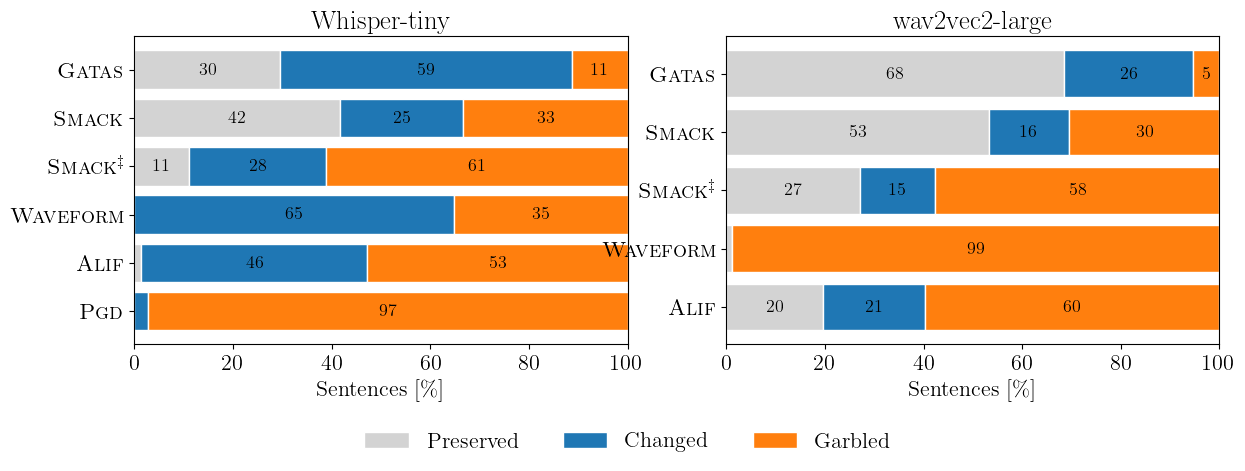

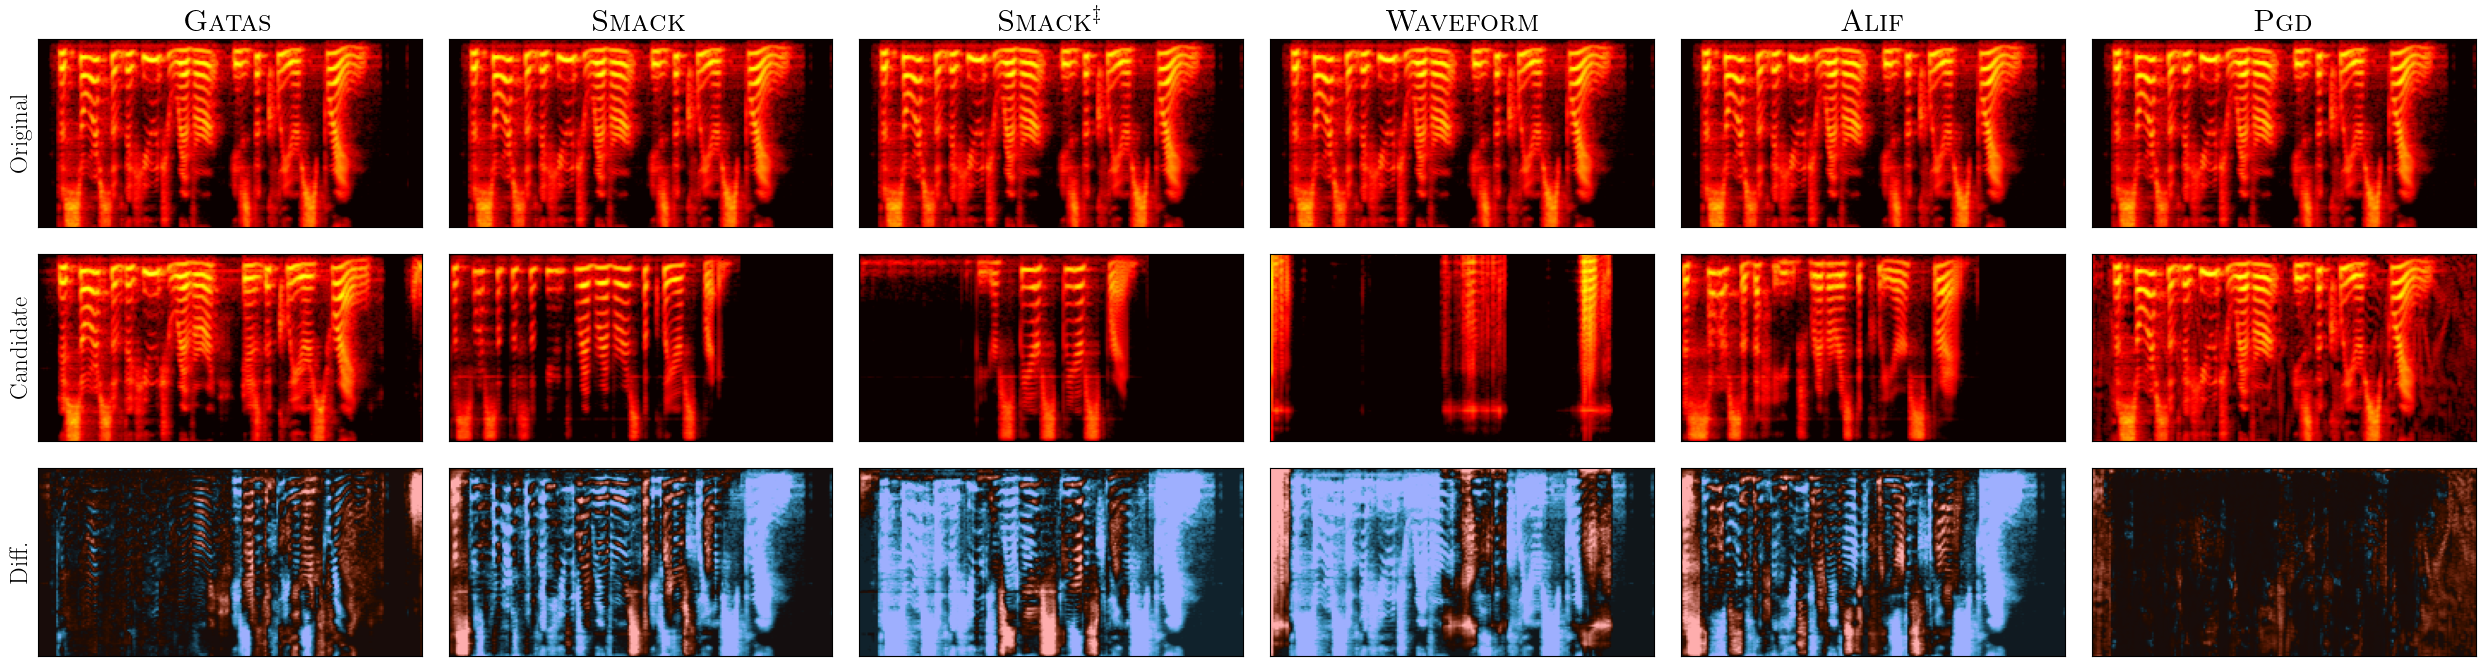

In [6]:
def to_spectrogram(file):
    y, sr = librosa.load(file, sr=None)
    return librosa.power_to_db(np.abs(librosa.feature.melspectrogram(y=y, sr=sr, n_fft=1024, hop_length=256, n_mels=128)))

def fit(spec, T):
    if spec.shape[1] < T:
        spec = np.pad(spec, ((0, 0), (0, T - spec.shape[1])), constant_values=spec.min())
    return spec[:, :T]

def spectrogram_grid(records, sentence_id, tag):
    ms = ordered(m for m, rs in records.items() if any(r["sentence_id"] == sentence_id for r in rs))
    fig, axes = plt.subplots(3, len(ms), figsize=(4.2 * len(ms), 7), squeeze=False)
    for j, m in enumerate(ms):
        r = next(r for r in records[m] if r["sentence_id"] == sentence_id)
        g, b = to_spectrogram(r["gt_wav"]), to_spectrogram(r["adv_wav"])
        T = max(g.shape[1], b.shape[1]); g, b = fit(g, T), fit(b, T)
        for i, (img, title) in enumerate(zip([g, b, b - g], ["Original", "Candidate", "Diff."])):
            ax = axes[i, j]
            if i < 2:
                ax.imshow(img, cmap="hot", vmin=-60, vmax=40, aspect="auto")
            else:
                ax.imshow(img, cmap="berlin", norm=TwoSlopeNorm(vmin=-40, vcenter=0, vmax=40), aspect="auto")
            ax.set_xticks([]); ax.set_yticks([])
            if j == 0: ax.set_ylabel(title)
            if i == 0: ax.set_title(tex_name(m))
    plt.tight_layout()
    plt.savefig(f"_figures/spec_{tag}_{sentence_id:03d}.jpg", dpi=200, bbox_inches="tight")
    plt.show()

spectrogram_grid(asr[PRIMARY], 13, "asr")

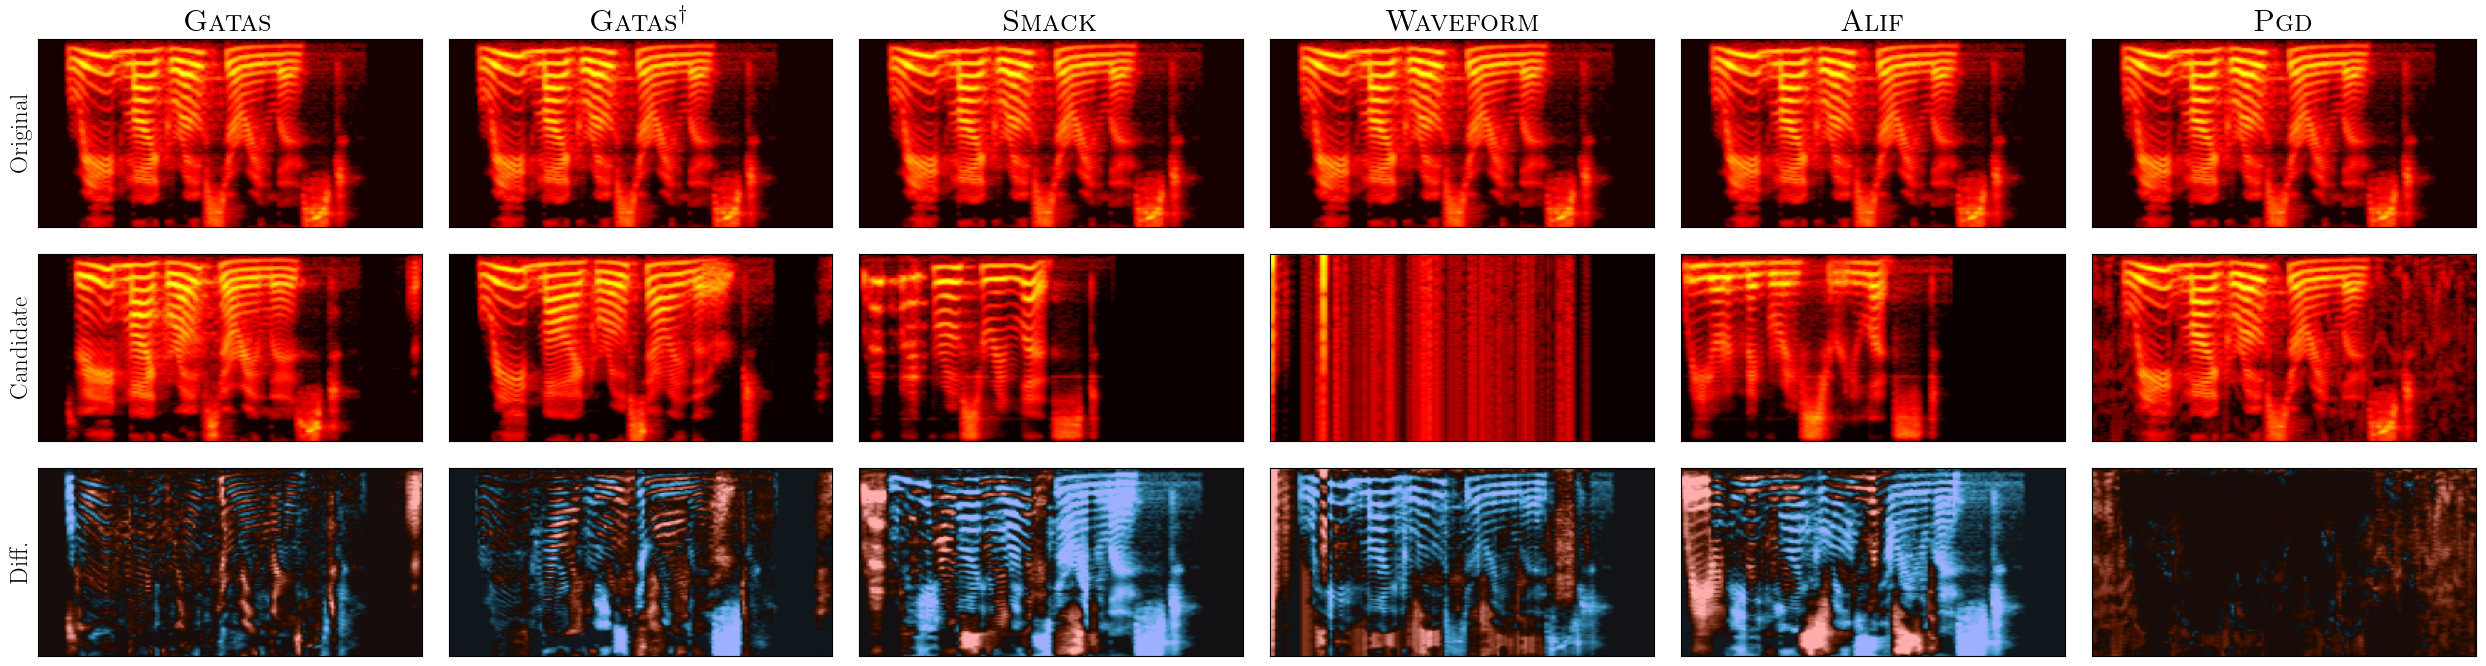

In [7]:
ia = intent[PRIMARY]
common = sorted(set.intersection(*(set(r["sentence_id"] for r in rs) for rs in ia.values())))
spectrogram_grid(ia, common[0], "intent")

## Statistical analysis
GATAS vs. every other method, paired by sentence. Binary measures: exact McNemar, difference of proportions (bootstrap CI), odds ratio of discordant pairs. Continuous measures: Wilcoxon signed-rank, paired Cohen's d_z with bootstrap CI. Two-sided, Holm-corrected per measure.

In [8]:
asr_metrics = {
    "test case found": (lambda r: float(asr_found(r)), True, "two-sided"),
    "WER": (lambda r: r["wer"], False, "two-sided"),
    "semantic": (lambda r: r["semantic"], False, "two-sided"),
    "spectrogram": (lambda r: r["spectrogram"], False, "two-sided"),
    "UTMOS": (lambda r: r["utmos"], False, "two-sided"),
}
pd.set_option("display.width", 250); pd.set_option("display.max_colwidth", 60)
for model in MODELS:
    print(f"ASR task, {MODEL_LABELS[model]}")
    display(pretty(comparison_table(asr[model], "GATAS", asr_metrics)))

ASR task, Whisper-tiny


,metric,vs,n,GATAS,other,diff [95% CI],p,effect,p (Holm)
0,test case found,Waveform,70,0.885714,1.000000,"-0.114 [-0.200, -0.043]",7.812500e-03,odds ratio=0.00,3.906250e-02
1,test case found,SMACK‡,71,0.887324,0.901408,"-0.014 [-0.127, 0.099]",1.000000e+00,odds ratio=0.88,1.000000e+00
2,test case found,ALIF,71,0.887324,1.000000,"-0.113 [-0.197, -0.042]",7.812500e-03,odds ratio=0.00,3.906250e-02
3,test case found,PGD,71,0.887324,1.000000,"-0.113 [-0.197, -0.042]",7.812500e-03,odds ratio=0.00,3.906250e-02
4,test case found,SMACK,71,0.887324,0.690141,"0.197 [0.056, 0.338]",1.612480e-02,odds ratio=2.75,3.906250e-02
5,WER,Waveform,70,0.189836,1.182143,"-0.992 [-1.393, -0.773]",4.686043e-13,"d_z=-0.63 [-7.32, -0.51]",1.874417e-12
6,WER,SMACK‡,71,0.190683,1.204907,"-1.014 [-1.584, -0.548]",5.630354e-11,"d_z=-0.44 [-1.23, -0.40]",1.126071e-10
7,WER,ALIF,71,0.190683,1.252951,"-1.062 [-1.931, -0.430]",4.790188e-12,"d_z=-0.32 [-1.47, -0.28]",1.437056e-11
8,WER,PGD,71,0.190683,1.453823,"-1.263 [-1.926, -0.904]",3.500046e-13,"d_z=-0.50 [-3.35, -0.42]",1.750023e-12
9,WER,SMACK,71,0.190683,0.668159,"-0.477 [-1.087, -0.131]",4.830163e-04,"d_z=-0.21 [-0.65, -0.17]",4.830163e-04


ASR task, wav2vec2-large


,metric,vs,n,GATAS,other,diff [95% CI],p,effect,p (Holm)
0,test case found,Waveform,92,0.934783,1.000000,"-0.065 [-0.120, -0.022]",3.125000e-02,odds ratio=0.00,9.375000e-02
1,test case found,SMACK‡,92,0.934783,0.847826,"0.087 [0.000, 0.185]",1.153183e-01,odds ratio=2.33,1.153183e-01
2,test case found,ALIF,92,0.934783,1.000000,"-0.065 [-0.120, -0.022]",3.125000e-02,odds ratio=0.00,9.375000e-02
3,test case found,SMACK,92,0.934783,0.739130,"0.196 [0.098, 0.293]",2.771616e-04,odds ratio=7.00,1.108646e-03
4,WER,Waveform,92,0.161025,0.988354,"-0.827 [-0.855, -0.796]",8.990084e-17,"d_z=-5.76 [-9.67, -4.07]",3.596034e-16
5,WER,SMACK‡,92,0.161025,0.609623,"-0.449 [-0.537, -0.363]",5.728143e-13,"d_z=-1.05 [-1.32, -0.84]",1.145629e-12
6,WER,ALIF,92,0.161025,0.548344,"-0.387 [-0.431, -0.342]",7.582596e-16,"d_z=-1.75 [-2.19, -1.43]",2.274779e-15
7,WER,SMACK,92,0.161025,0.340601,"-0.180 [-0.253, -0.109]",1.147968e-05,"d_z=-0.51 [-0.68, -0.36]",1.147968e-05
8,semantic,Waveform,92,0.188686,0.913948,"-0.725 [-0.761, -0.688]",8.422199e-17,"d_z=-4.07 [-5.45, -3.25]",3.368880e-16
9,semantic,SMACK‡,92,0.188686,0.504343,"-0.316 [-0.393, -0.240]",4.322442e-10,"d_z=-0.84 [-1.11, -0.63]",8.644884e-10


In [9]:
intent_metrics = {
    "intent changed": (lambda r: float(r["intent"]["changed"]), True, "two-sided"),
    "target hit": (lambda r: float(intent_hit(r)), True, "two-sided"),
    **{k: v for k, v in asr_metrics.items() if k != "test case found"},
}
for model in MODELS:
    print(f"Intent matching task, {MODEL_LABELS[model]}")
    display(pretty(comparison_table(intent[model], "GATAS", intent_metrics)))

Intent matching task, Whisper-tiny


,metric,vs,n,GATAS,other,diff [95% CI],p,effect,p (Holm)
0,intent changed,Waveform,98,0.204082,0.826531,"-0.622 [-0.724, -0.520]",1.163349e-16,odds ratio=0.03,3.490047e-16
1,intent changed,SMACK,98,0.204082,0.459184,"-0.255 [-0.367, -0.133]",1.122214e-04,odds ratio=0.24,1.122214e-04
2,intent changed,ALIF,98,0.204082,0.663265,"-0.459 [-0.571, -0.347]",7.053980e-11,odds ratio=0.08,1.410796e-10
3,intent changed,PGD,98,0.204082,0.918367,"-0.714 [-0.806, -0.612]",2.939204e-19,odds ratio=0.03,1.175682e-18
4,intent changed,GATAS†,98,0.204082,0.846939,"-0.643 [-0.735, -0.551]",2.168404e-19,odds ratio=0.00,1.084202e-18
5,target hit,Waveform,98,0.091837,0.204082,"-0.112 [-0.194, -0.041]",7.385254e-03,odds ratio=0.15,2.215576e-02
6,target hit,SMACK,98,0.091837,0.061224,"0.031 [-0.031, 0.092]",5.078125e-01,odds ratio=2.00,1.000000e+00
7,target hit,ALIF,98,0.091837,0.367347,"-0.276 [-0.378, -0.173]",1.401175e-06,odds ratio=0.10,5.604699e-06
8,target hit,PGD,98,0.091837,0.061224,"0.031 [-0.031, 0.092]",5.078125e-01,odds ratio=2.00,1.000000e+00
9,target hit,GATAS†,98,0.091837,0.734694,"-0.643 [-0.735, -0.551]",2.168404e-19,odds ratio=0.00,1.084202e-18


Intent matching task, wav2vec2-large


,metric,vs,n,GATAS,other,diff [95% CI],p,effect,p (Holm)
0,intent changed,Waveform,58,0.155172,0.844828,"-0.690 [-0.828, -0.534]",1.513833e-09,odds ratio=0.09,6.055330e-09
1,intent changed,SMACK,58,0.155172,0.327586,"-0.172 [-0.310, -0.034]",4.138947e-02,odds ratio=0.33,4.138947e-02
2,intent changed,ALIF,58,0.155172,0.568966,"-0.414 [-0.569, -0.259]",8.430332e-06,odds ratio=0.11,1.686066e-05
3,intent changed,GATAS†,58,0.155172,0.706897,"-0.552 [-0.690, -0.414]",4.074536e-09,odds ratio=0.03,1.222361e-08
4,target hit,Waveform,58,0.000000,0.189655,"-0.190 [-0.293, -0.103]",9.765625e-04,odds ratio=0.00,1.953125e-03
5,target hit,SMACK,58,0.000000,0.017241,"-0.017 [-0.052, 0.000]",1.000000e+00,odds ratio=0.00,1.000000e+00
6,target hit,ALIF,58,0.000000,0.241379,"-0.241 [-0.345, -0.138]",1.220703e-04,odds ratio=0.00,3.662109e-04
7,target hit,GATAS†,58,0.000000,0.431034,"-0.431 [-0.552, -0.310]",5.960464e-08,odds ratio=0.00,2.384186e-07
8,WER,Waveform,58,0.220042,0.852205,"-0.632 [-0.710, -0.546]",2.080732e-10,"d_z=-1.92 [-2.98, -1.37]",8.322929e-10
9,WER,SMACK,58,0.220042,0.528998,"-0.309 [-0.433, -0.198]",5.144637e-06,"d_z=-0.66 [-0.89, -0.48]",5.144637e-06


## RQ1 paper table (`_tables/rq1.tex`)

One table, panels for ASR testing and intent matching, column groups per attacked model: test cases found (ASR: transcription differs; intent: intent changed and target hit), WER, semantic and spectrogram distance, UTMOS and the share of m-valid test cases (UTMOS threshold per task, `task_thresholds`). The reference method is GATAS on ASR and GATAS$^\dagger$ (GATAS_llm) on intent matching. A baseline cell is **shaded** when the reference is significantly better in this model, task and measure: one-sided paired tests (exact McNemar for the rates, Wilcoxon signed-rank for the continuous measures), Holm-corrected over the baselines, p < 0.05; the paired Cohen's d_z (also for the 0/1 measures; positive: reference better) is printed in the cell. The two-sided analyses above stay as the exhaustive statistics.

In [10]:
import os
os.makedirs("_tables", exist_ok=True)
for old in ("rq1_stats", "rq1_full", "rq1_intent_full", "rq1_intent"):  # replaced by the single table
    if os.path.exists(f"_tables/{old}.tex"):
        os.remove(f"_tables/{old}.tex")
tex = pt.rq1_tex(asr, intent, thr)
open("_tables/rq1.tex", "w").write(tex + "\n")
print("% tables/rq1.tex"); print(tex)

% tables/rq1.tex
\begin{table*}[t]
\caption{Effectiveness (RQ\textsubscript{1}) on (a) ASR testing and (b) intent matching: test cases found, lexical (WER), semantic and spectrogram distance to the clean audio, naturalness (UTMOS) and the share of m-valid test cases. Bold: best value. \colorbox{gray!25}{Shaded}: the reference method (\tool on ASR, \gllm on intent matching) is significantly better than this method in this model and measure (one-sided paired test, Holm-corrected, $p<0.05$), with the paired Cohen's $d_z$ as subscript. \pgd is white-box on Whisper and has no wav2vec2 run.}
\label{tab:rq1}
\centering
\small
\textbf{(a) ASR testing}\\[2pt]
\resizebox{\textwidth}{!}{%
\begin{tabular}{lcccccccccccc}\toprule
 & \multicolumn{6}{c}{Whisper-tiny} & \multicolumn{6}{c}{wav2vec2-large} \\
\cmidrule(lr){2-7}\cmidrule(lr){8-13}
 & Found [\%] $\uparrow$ & WER $\downarrow$ & Semantic $\downarrow$ & $d_F$-Spec $\downarrow$ & UTMOS $\uparrow$ & M-valid [\%] $\uparrow$ & Found [\%] $\uparro

## LLM semantic table (separate, `_tables/llm_semantic.tex`)

In [11]:
tex = pt.llm_semantic_tex(asr)
open("_tables/llm_semantic.tex", "w").write(tex + "\n")
print("% tables/llm_semantic.tex"); print(tex)

% tables/llm_semantic.tex
\begin{table}[t]
\caption{Semantic outcome of the ASR transcriptions judged by a local LLM [\%]: same meaning (preserved), coherent but different meaning (changed), incoherent (garbled). \pgd is white-box on Whisper and has no wav2vec2 run.}
\label{tab:llm-semantic}
\centering
\resizebox{\columnwidth}{!}{%
\begin{tabular}{lcccccc}\toprule
 & \multicolumn{3}{c}{Whisper-tiny} & \multicolumn{3}{c}{wav2vec2-large} \\
\cmidrule(lr){2-4}\cmidrule(lr){5-7}
 & Preserved & Changed & Garbled & Preserved & Changed & Garbled \\ \midrule
\tool & 29.6 & 59.2 & 11.3 & 68.5 & 26.1 & 5.4 \\
\wv & 0.0 & 64.8 & 35.2 & 1.1 & 0.0 & 98.9 \\
\smack$^\ddagger$ & 11.1 & 27.8 & 61.1 & 27.2 & 15.2 & 57.6 \\
\smack & 41.7 & 25.0 & 33.3 & 53.3 & 16.3 & 30.4 \\
\alif & 1.4 & 45.8 & 52.8 & 19.6 & 20.7 & 59.8 \\
\pgd & 0.0 & 2.8 & 97.2 & -- & -- & -- \\
\bottomrule
\end{tabular}}
\end{table}
